# Notebook 4: The Threshold

The model calls a case determinate when the net force clears a threshold:
`|F| > tau`. Notebook 6 showed that this one number, tau, governs ~85% of how
often the model decides anything -- it is the most consequential dial in the whole
apparatus. This notebook asks the obvious next question: **where does tau come
from, and how much should we trust it?**

The honest answer starts with Berman himself. He does **not** decide cases by a
threshold. He reads legal force by its **sign**: there is law for the result with
the greater net force, and genuine indeterminacy only at near-cancellation -- and
he *welcomes* that underdeterminacy (HPMP pp. 326, 329 n.94, 334). In his own
terms, `tau = 0`. So a positive threshold is **ours**, an operationalization of
'determinate enough to count,' and its value is a modeling choice, not a fact
about the theory. Berman put the challenge to us directly: *do you have an argument
for why principled positivism needs a nonzero threshold?*

### What this notebook establishes
1. There is **no privileged tau**. The determinacy rate is a smooth, monotone
   function of tau with no special point; 0, 0.137, 0.20, and 0.255 are just points
   on one curve. (Cross-checked against Notebook 7's closed form.)
2. If you *do* want a positive band, the principled way to set it is
   **verdict-robustness** -- the tau below which verdicts survive realistic noise.
   But robustness rises monotonically with tau, so it pins a **confidence level**,
   not a unique number; it yields a defensible *bracket* (~0.07 to ~0.27, with the
   conventional 0.20 inside it).
3. The old **learned tau = 0.255 is an artifact** and we retract it: it optimized
   neither objective it was credited with.
4. The paper's **substantive conclusions do not hinge on tau** -- determinacy
   behaviour and the R1-R4 verdicts on the emergent weights hold across the whole
   range down to Berman's 0, and the mechanism ranking is invariant for every
   tau >= 0.025 (at exactly 0 all mechanisms are ~100% determinate, so it ties).

### The honest line, kept throughout
This part defends a **choice**; it does not discover a true tau. Berman would
accept tau = 0, and our conclusions hold across the band either way.

## Setup

On Colab this mounts your Google Drive and works inside the project folder so the
outputs persist; locally it uses the current folder. The next cell writes the
shared core, then imports it.

In [1]:
import os
PROJECT = '/content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06'
try:
    from google.colab import drive            # on Colab: mount Drive and work in the project folder
    drive.mount('/content/drive')
    os.makedirs(PROJECT, exist_ok=True); os.chdir(PROJECT)
    print('Colab: mounted Drive, working in', os.getcwd())
except ImportError:
    print('Local: working in', os.getcwd())

Mounted at /content/drive
Colab: mounted Drive, working in /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06


In [2]:
%%writefile berman_core.py
"""
berman_core.py — shared, corrected core for the Berman Modeling rebuild (2026-06).

ONE source of truth for the SAW model, principle sets, Hart baselines, a *seeded*
bootstrap, the activation generators, the weight-tolerance (critical-sigma)
machinery, and the redesigned evaluation criteria. Every notebook %%writefile's
this file and `from berman_core import *`, so a fix here propagates everywhere
(ends the verbatim-copy drift of the old notebooks).

Design decisions baked in (vs. the old code):
  * Determinacy convention is strict |F| > tau, matching the manuscript.
  * RNG is always explicit (np.random.default_rng(seed)); bootstrap is seeded
    and vectorized, so every CI is reproducible.
  * One determinacy cutoff (DEFAULT_TAU) everywhere — no 0.05-here-0.2-there.
  * Corrected category map: federalism is STRUCTURAL, not moral.
  * Criteria are split into REQUIREMENTS (R1-R4, pass/fail, derived from what
    Berman actually claims) and DESCRIPTIVE measures (D1-D2, reported, never used
    to fail the theory). See CONCEPTUAL_AUDIT_vs_Berman.md.
"""
from __future__ import annotations

from dataclasses import dataclass
from typing import Dict, List, Optional, Callable, Tuple

import numpy as np

__all__ = [
    "DEFAULT_TAU", "Principle", "NAMED_PRINCIPLES", "CATEGORY_INDEX",
    "make_weights", "named_weight_vector", "category_of",
    "net_force", "is_determinate", "determinacy_rate",
    "random_activations", "category_correlated_activations", "fully_correlated_activations",
    "bootstrap_ci", "critical_sigma", "CRITICAL_SIGMA_CEIL",
    "hart_hierarchical_determinate", "hart_consensus_determinate", "hart_advantage",
    "hart_validation_status",
    "nonlexicality_score", "ordinalize", "saw_verdict", "lexicographic_verdict",
    "weight_cv", "n_survivors", "cluster_gap",
    "METHODOLOGIES", "methodology_tendencies", "LegalSystem",
    "gmm_bimodal", "bimodality_coefficient",
    "RelianceSystem", "weight_entropy", "gini", "n_bins_occupied",
    "set_determinism", "StrategicSystem",
    "verdict_flip_rates", "system_flip_curve", "principled_tau_percase",
]

# ---------------------------------------------------------------------------
# Determinacy convention
# ---------------------------------------------------------------------------
DEFAULT_TAU: float = 0.20  # a case is determinate when |F| > tau (strict)


# ---------------------------------------------------------------------------
# Principles and categories  (federalism corrected to 'structural')
# ---------------------------------------------------------------------------
@dataclass
class Principle:
    name: str
    weight: float
    category: str = "structural"  # one of: 'textual', 'structural', 'moral'

    def __post_init__(self) -> None:
        assert 0.0 <= self.weight <= 1.0, f"weight out of [0,1]: {self.weight}"
        assert self.category in ("textual", "structural", "moral"), self.category


# The baseline 9-principle set. Order is fixed; categories are the corrected map.
NAMED_PRINCIPLES: List[Tuple[str, str]] = [
    ("text",       "textual"),
    ("original",   "textual"),
    ("precedent",  "structural"),
    ("structure",  "structural"),
    ("federalism", "structural"),   # <-- was grouped with 'moral' in the old code (bug)
    ("dignity",    "moral"),
    ("equality",   "moral"),
    ("liberty",    "moral"),
    ("welfare",    "moral"),
]

CATEGORY_INDEX: Dict[str, List[int]] = {
    cat: [i for i, (_, c) in enumerate(NAMED_PRINCIPLES) if c == cat]
    for cat in ("textual", "structural", "moral")
}


def category_of(i: int) -> str:
    return NAMED_PRINCIPLES[i][1]


# ---------------------------------------------------------------------------
# Weight generators
# ---------------------------------------------------------------------------
def make_weights(n: int, distribution: str, seed: int) -> np.ndarray:
    """Generate n weights. 'uniform' ~U(.60,.70); 'moderate' ~U(.50,.80);
    'high' ~U(.30,.95). Berman's weights are 'rough' (slight..nearly conclusive)."""
    rng = np.random.default_rng(seed)
    if distribution == "uniform":
        return rng.uniform(0.60, 0.70, n)
    if distribution == "moderate":
        return rng.uniform(0.50, 0.80, n)
    if distribution == "high":
        return rng.uniform(0.30, 0.95, n)
    raise ValueError(f"unknown distribution: {distribution}")


def named_weight_vector(distribution: str = "moderate", seed: int = 0) -> np.ndarray:
    """Weights for the 9 NAMED_PRINCIPLES under a given distribution."""
    return make_weights(len(NAMED_PRINCIPLES), distribution, seed)


# ---------------------------------------------------------------------------
# SAW model (nonlexical aggregation)
# ---------------------------------------------------------------------------
def net_force(weights: np.ndarray, activations: np.ndarray) -> np.ndarray:
    """F = sum_i w_i * a_i. Vectorized over a (..., n) activation array."""
    weights = np.asarray(weights, float)
    activations = np.asarray(activations, float)
    return np.sum(weights * activations, axis=-1)


def is_determinate(weights, activations, tau: float = DEFAULT_TAU):
    return np.abs(net_force(weights, activations)) > tau


def determinacy_rate(weights, activation_matrix, tau: float = DEFAULT_TAU) -> float:
    return float(np.mean(is_determinate(weights, activation_matrix, tau)))


# ---------------------------------------------------------------------------
# Activation generators (the conservative independent baseline + realistic structure)
# ---------------------------------------------------------------------------
def random_activations(n_cases: int, n_principles: int, rng: np.random.Generator) -> np.ndarray:
    """Independent activations ~ U(-1, 1). The conservative baseline."""
    return rng.uniform(-1.0, 1.0, size=(n_cases, n_principles))


def category_correlated_activations(n_cases: int, rng: np.random.Generator,
                                    rho: float = 0.7) -> np.ndarray:
    """Activations for the 9 NAMED_PRINCIPLES where principles in the same
    category share a common latent factor (textual together, structural together,
    moral together)."""
    n_p = len(NAMED_PRINCIPLES)
    a = np.empty((n_cases, n_p))
    for cat, idx in CATEGORY_INDEX.items():
        factor = rng.uniform(-1.0, 1.0, size=(n_cases, 1))
        idio = rng.uniform(-1.0, 1.0, size=(n_cases, len(idx)))
        a[:, idx] = np.clip(rho * factor + (1 - rho) * idio, -1.0, 1.0)
    return a


def fully_correlated_activations(n_cases: int, n_principles: int,
                                 rng: np.random.Generator, rho: float = 0.7) -> np.ndarray:
    """All principles share one latent factor."""
    factor = rng.uniform(-1.0, 1.0, size=(n_cases, 1))
    idio = rng.uniform(-1.0, 1.0, size=(n_cases, n_principles))
    return np.clip(rho * factor + (1 - rho) * idio, -1.0, 1.0)


# ---------------------------------------------------------------------------
# Bootstrap — SEEDED and vectorized (every CI is reproducible)
# ---------------------------------------------------------------------------
def bootstrap_ci(values, n_boot: int = 2000, ci: int = 95, seed: int = 0):
    """Return (mean, lo, hi) for a percentile bootstrap CI on the mean."""
    rng = np.random.default_rng(seed)
    arr = np.asarray(values, dtype=float)
    if arr.size == 0:
        return (float("nan"),) * 3
    means = rng.choice(arr, size=(n_boot, arr.size), replace=True).mean(axis=1)
    lo = float(np.percentile(means, (100 - ci) / 2))
    hi = float(np.percentile(means, 100 - (100 - ci) / 2))
    return float(arr.mean()), lo, hi


# ---------------------------------------------------------------------------
# Weight-uncertainty tolerance: critical sigma  (R2 — "rough weights suffice")
# ---------------------------------------------------------------------------
CRITICAL_SIGMA_CEIL = 1.0  # grid maximum; a returned value == this is right-censored


def critical_sigma(weights: np.ndarray, activation_matrix: np.ndarray,
                   tau: float = DEFAULT_TAU, accuracy: float = 0.80,
                   robust_thresh: float = 0.90, n_mc: int = 64, seed: int = 0,
                   sigma_grid: Optional[np.ndarray] = None) -> float:
    """Smallest weight-noise sigma at which fewer than `accuracy` of cases remain
    individually robust.

    Two-level definition: add N(0, sigma^2) to each weight (clipped to [0,1]); a
    *case* is robust at sigma if it keeps its unperturbed signed VERDICT
    (determinate-for / determinate-against / indeterminate) on at least
    `robust_thresh` of MC draws; sigma* is the smallest sigma at which the
    fraction of robust cases falls below `accuracy`.

    Verdict-stability (not just determinate/indeterminate class) so that a noise
    level that flips a determinate-for case to determinate-against counts as
    instability. The grid runs to CRITICAL_SIGMA_CEIL; a returned value equal to
    the ceiling is right-censored (true tolerance is >= ceiling) -- callers
    should flag these rather than average them as if measured.
    """
    rng = np.random.default_rng(seed)
    w = np.asarray(weights, float)
    A = np.asarray(activation_matrix, float)
    n_p = w.size
    if sigma_grid is None:
        sigma_grid = np.linspace(0.0, CRITICAL_SIGMA_CEIL, 51)

    true_F = A @ w
    true_v = np.sign(true_F); true_v[np.abs(true_F) <= tau] = 0    # (cases,) verdict
    noise = rng.standard_normal((n_mc, A.shape[0], n_p))          # (mc, cases, p)

    prev_sigma, prev_surv = 0.0, 1.0
    for sigma in sigma_grid:
        if sigma == 0:
            prev_sigma, prev_surv = 0.0, 1.0
            continue
        w_noisy = np.clip(w[None, None, :] + sigma * noise, 0.0, 1.0)
        F = np.einsum("mcp,cp->mc", w_noisy, A)                   # (mc, cases)
        v = np.sign(F); v[np.abs(F) <= tau] = 0
        agree_frac = np.mean(v == true_v[None, :], axis=0)        # per case
        survival = float(np.mean(agree_frac >= robust_thresh))
        if survival < accuracy:
            frac = (accuracy - prev_surv) / (survival - prev_surv)
            return float(prev_sigma + frac * (sigma - prev_sigma))
        prev_sigma, prev_surv = sigma, survival
    return float(sigma_grid[-1])  # right-censored at the ceiling


# ---------------------------------------------------------------------------
# Hart baselines  (R4 — "more law than Hart", reported as a margin/curve)
# ---------------------------------------------------------------------------
def hart_consensus_determinate(activations, frac: float = 0.6,
                               act_cut: float = 0.1) -> np.ndarray:
    """Consensus Hart (the faithful operationalization of Hart-as-validation):
    a case is determinate only when the share of *active* principles pointing the
    same direction exceeds `frac`. Hart requires agreement; below `frac` the law
    'runs out'."""
    A = np.atleast_2d(np.asarray(activations, float))
    pos = np.sum(A > act_cut, axis=1)
    neg = np.sum(A < -act_cut, axis=1)
    active = pos + neg
    with np.errstate(invalid="ignore", divide="ignore"):
        share = np.maximum(pos, neg) / np.where(active == 0, 1, active)
    return (active > 0) & (share > frac)


def hart_hierarchical_determinate(weights, activations, tier_of: np.ndarray,
                                  frac: float = 0.6, act_cut: float = 0.1,
                                  tau: float = DEFAULT_TAU) -> np.ndarray:
    """Charitable *lexical-priority* Hart: principles sit in priority tiers
    (0 = top). For each case, the highest-priority tier that has ANY active
    principle is DISPOSITIVE: that tier decides iff its active principles reach
    consensus (>= `frac` agree in sign); otherwise the law runs out. Lower tiers
    are NOT consulted once a higher tier is reached — that is the lexical priority
    Berman's nonlexical model is contrasted against, and it is what stops Hart
    from finding law in nearly every case via tier escape-hatches.
    """
    A = np.atleast_2d(np.asarray(activations, float))
    tier_of = np.asarray(tier_of, int)
    out = np.zeros(A.shape[0], dtype=bool)
    reached = np.zeros(A.shape[0], dtype=bool)  # a dispositive tier has been reached
    for t in np.unique(tier_of):
        idx = np.where(tier_of == t)[0]
        sub = A[:, idx]
        pos = np.sum(sub > act_cut, axis=1)
        neg = np.sum(sub < -act_cut, axis=1)
        active = pos + neg
        this_tier = (active > 0) & (~reached)        # cases first resolved at this tier
        with np.errstate(invalid="ignore", divide="ignore"):
            share = np.maximum(pos, neg) / np.where(active == 0, 1, active)
        out |= this_tier & (share > frac)             # decided iff consensus here (strict, matches consensus Hart)
        reached |= this_tier                           # dispositive; no escape downward
    return out


def hart_validation_status(activations, k: int = 2, act_cut: float = 0.5) -> np.ndarray:
    """Naive validation foil used to make Berman's 'no contradiction' point.

    A direction counts as independently 'validated' when at least `k` principles
    are strongly activated (|a| > act_cut) in that direction. Returns one integer
    code per case:
        0 = gap          (neither direction validated -> the law runs out)
        1 = for          (only the positive direction validated)
        2 = against      (only the negative direction validated)
        3 = contradiction(both directions validated -> q and not-q are both law)

    The point: code 3 is possible for a validation model, but impossible for
    Berman's aggregation, because a single net force has a single sign. So the sum
    never returns code 3.
    """
    A = np.atleast_2d(np.asarray(activations, float))
    pos = np.sum(A > act_cut, axis=1) >= k
    neg = np.sum(A < -act_cut, axis=1) >= k
    code = np.zeros(A.shape[0], dtype=int)
    code[pos & ~neg] = 1
    code[neg & ~pos] = 2
    code[pos & neg] = 3
    return code


def hart_advantage(weights, activation_matrix, tier_of, frac: float = 0.6,
                   tau: float = DEFAULT_TAU) -> float:
    """Berman determinacy rate minus hierarchical-Hart determinacy rate (a margin,
    not a pass/fail)."""
    berman = determinacy_rate(weights, activation_matrix, tau)
    hart = float(np.mean(hart_hierarchical_determinate(
        weights, activation_matrix, tier_of, frac=frac, tau=tau)))
    return berman - hart


# ---------------------------------------------------------------------------
# R3 — nonlexicality.  Does determination track activation MAGNITUDES (and many
# principles jointly), as Berman requires, rather than just signs/ranks (lexical)?
# ---------------------------------------------------------------------------
def ordinalize(weights: np.ndarray) -> np.ndarray:
    """Replace weights by rank-based pseudo-weights (1..n)/n — discards cardinal info."""
    order = np.argsort(np.argsort(weights))  # ranks 0..n-1
    return (order + 1) / len(weights)


# Verdict functions return an integer verdict per case: +1 / -1 (determinate for
# / against) or 0 (indeterminate). These are the inputs to the R3 nonlexicality
# probe and are reused by the aggregation-function suite.
def saw_verdict(weights, activation_matrix, tau: float = DEFAULT_TAU) -> np.ndarray:
    """Nonlexical: verdict from the *magnitude-weighted sum* of all principles."""
    F = np.asarray(activation_matrix, float) @ np.asarray(weights, float)
    v = np.sign(F)
    v[np.abs(F) <= tau] = 0
    return v.astype(int)


def lexicographic_verdict(weights, activation_matrix, act_cut: float = 0.05) -> np.ndarray:
    """Lexical: verdict from the SIGN of the single highest-weight active
    principle (Raz exclusionary-reasons style). This is the mode Berman's theory
    is defined against — included only as the lexical foil for the R3 probe."""
    w = np.asarray(weights, float)
    A = np.atleast_2d(np.asarray(activation_matrix, float))
    order = np.argsort(-w)  # highest weight first
    out = np.zeros(A.shape[0], dtype=int)
    decided = np.zeros(A.shape[0], dtype=bool)
    for j in order:
        active = (np.abs(A[:, j]) > act_cut) & (~decided)
        out[active] = np.sign(A[active, j]).astype(int)
        decided |= active
    return out


def nonlexicality_score(verdict_fn: Callable[[np.ndarray], np.ndarray],
                        activation_matrix: np.ndarray,
                        seed: int = 0, n_mc: int = 32, jitter: float = 0.20) -> float:
    """R3 probe. Fraction of cases whose VERDICT changes under a magnitude-only
    perturbation of activations that preserves every activation's sign AND the
    within-case rank order of |activation|.

    A lexical rule (decides on the top-ranked active principle) is invariant to
    such perturbations -> score ~ 0. A genuinely nonlexical, magnitude-aggregating
    rule (SAW) is sensitive -> score > 0. `verdict_fn(A)` maps an (n,9) activation
    matrix to an integer verdict array in {-1,0,+1}.
    """
    rng = np.random.default_rng(seed)
    A = np.asarray(activation_matrix, float)
    base = verdict_fn(A)
    rank = np.argsort(np.argsort(np.abs(A), axis=1), axis=1)  # rank of |a| within row
    n_p = A.shape[1]
    changed = np.zeros(A.shape[0])
    for _ in range(n_mc):
        mag = np.clip(np.abs(A) * (1 + rng.uniform(-jitter, jitter, A.shape)), 0, 1)
        sorted_mag = np.sort(mag, axis=1)
        # Strictly-increasing epsilon breaks ties created when two magnitudes both
        # clip to 1.0; without this, re-placing tied values by index can silently
        # change the rank order (and thus the decision of a lexical rule). This
        # guarantees |A2| keeps the ORIGINAL within-row rank order exactly.
        sorted_mag = sorted_mag + 1e-9 * np.arange(n_p)
        A2 = np.sign(A) * np.take_along_axis(sorted_mag, rank, axis=1)
        changed += (verdict_fn(A2) != base)
    return float(np.mean(changed / n_mc))


# ---------------------------------------------------------------------------
# Descriptive weight statistics (D1 gradation, and emergence diagnostics)
# ---------------------------------------------------------------------------
def weight_cv(weights: np.ndarray) -> float:
    w = np.asarray(weights, float)
    m = w.mean()
    return float(w.std() / m) if m > 0 else 0.0


def n_survivors(weights: np.ndarray, cutoff: float = 0.05) -> int:
    return int(np.sum(np.asarray(weights, float) > cutoff))


def cluster_gap(weights: np.ndarray) -> float:
    """Gap between the two k-means clusters of weights (bimodality diagnostic)."""
    w = np.sort(np.asarray(weights, float))
    if w.size < 2:
        return 0.0
    best = None
    for k in range(1, w.size):
        lo, hi = w[:k], w[k:]
        gap = hi.mean() - lo.mean()
        if best is None or gap > best:
            best = gap
    return float(best)


# ===========================================================================
# Agent-based model of weight emergence (Notebook 1)
# ===========================================================================
# A bench of judges, each carrying an interpretive methodology that sets how
# often it invokes each principle. A principle's emergent "uptake share" is how
# often the bench takes it up across decisions. This is a deliberately simple
# model of Berman's "taking-up" (JESP p. 302); it is NOT his full account of
# weight, which is conferred by reliance and by winning conflicts (pp. 322, 324)
# and is taken up in Notebook 1c. The emergent quantity here is called "uptake
# share," never "weight in Berman's sense."

METHODOLOGIES = ("textualist", "purposivist", "pragmatist", "originalist")

# For each methodology, the principles it tends to invoke often ('high') or
# rarely ('low'); anything unlisted is 'medium'. Names refer to NAMED_PRINCIPLES.
_METH_SETS = {
    "textualist":  {"high": {"text", "original"},
                    "low":  {"dignity", "equality", "liberty", "welfare"}},
    "purposivist": {"high": {"dignity", "equality", "liberty"},
                    "low":  {"text", "original", "federalism"}},
    "pragmatist":  {"high": {"welfare", "precedent"},
                    "low":  {"dignity", "equality", "original"}},
    "originalist": {"high": {"original", "text", "federalism"},
                    "low":  {"dignity", "equality", "liberty", "welfare"}},
}

# Invocation-probability ranges (high, medium, low) by how specialized the
# methodologies are. 'wide' = strong specialization (headline); 'narrow' = nearly
# homogeneous (used to show heterogeneity is necessary for the split).
_SPREAD_RANGES = {
    "wide":   ((0.85, 0.95), (0.35, 0.65), (0.02, 0.08)),
    "medium": ((0.70, 0.80), (0.40, 0.60), (0.15, 0.25)),
    "narrow": ((0.60, 0.70), (0.42, 0.58), (0.30, 0.40)),
}


def methodology_tendencies(methodology: str, spread: str, rng) -> np.ndarray:
    """A 9-vector of per-principle invocation probabilities for one judge of a
    given methodology, drawn from the high/medium/low ranges set by `spread`."""
    hi, med, lo = _SPREAD_RANGES[spread]
    sets = _METH_SETS[methodology]
    t = np.empty(len(NAMED_PRINCIPLES))
    for i, (name, _) in enumerate(NAMED_PRINCIPLES):
        rng_range = hi if name in sets["high"] else (lo if name in sets["low"] else med)
        t[i] = rng.uniform(*rng_range)
    return t


class LegalSystem:
    """A bench of judges whose case-by-case invocations produce emergent
    principle uptake-shares.

    `turnover` selects how judges are replaced over time:
      'static'      no replacement (the headline emergence must hold here);
      'fitness'     replace the least decisive 20% with mutated copies of the
                    most decisive 20% (the old, suspect, non-Bermanian rule);
      'appointment' replace a random 20%, reseated from the methodology pool;
      'noise'       replace a random 20% with mutated copies of random judges.
    The point of the four regimes is to show the emergent structure does NOT
    depend on the turnover rule.
    """

    def __init__(self, n_agents=100, methodology_mix=None, spread="wide",
                 use_threshold=True, threshold_pct=50, turnover="static",
                 boost_cut=0.3, learn_from_system=0.15, seed=0):
        # One master seed -> five independent streams. No global np.random.
        ss = np.random.SeedSequence(seed)
        (self._rng_agents, self._rng_panels, self._rng_cases,
         self._rng_dec, self._rng_rep) = (np.random.default_rng(s) for s in ss.spawn(5))
        self.n_agents = n_agents
        self.spread = spread
        self.use_threshold = use_threshold
        self.threshold_pct = threshold_pct
        self.turnover = turnover
        self.boost_cut = boost_cut
        self.learn_from_system = learn_from_system
        self.n_p = len(NAMED_PRINCIPLES)

        # Assign methodologies exactly (round-robin or a given mix), then permute
        # the arrangement with the seeded generator (never np.random.shuffle).
        if methodology_mix is None:
            base = [METHODOLOGIES[i % 4] for i in range(n_agents)]
        else:
            base = []
            for m, frac in methodology_mix.items():
                base += [m] * int(round(frac * n_agents))
            base = (base + [METHODOLOGIES[0]] * n_agents)[:n_agents]
        self.methodology = list(self._rng_agents.permutation(base))
        self.tendencies = np.array([methodology_tendencies(m, spread, self._rng_agents)
                                    for m in self.methodology])     # (n_agents, 9)
        self.system_weights = np.full(self.n_p, 0.5)                # uniform init
        self.raw_uptake = np.full(self.n_p, 0.5)                    # pre-threshold share
        self.success = np.zeros(n_agents)
        self.decisions = np.zeros(n_agents)
        self.trajectory = []

    def _recompute_weights(self, counts, total):
        raw = counts / max(total, 1)
        raw = raw / max(raw.max(), 1e-12)                           # normalize to max
        self.raw_uptake = raw.copy()                               # the pre-threshold vector
        w = raw.copy()
        if self.use_threshold:                                     # zero the bottom percentile
            cut = np.percentile(w, self.threshold_pct)
            w = np.where(w < cut, 0.0, w)
            if w.max() > 0:
                w = w / w.max()
        self.system_weights = w

    def _replace(self, idx_out, idx_template):
        for o, t in zip(idx_out, idx_template):
            self.methodology[o] = self.methodology[t]
            self.tendencies[o] = np.clip(self.tendencies[t] + self._rng_rep.normal(0, 0.03, self.n_p),
                                         0.02, 0.98)
            self.success[o] = 0.0
            self.decisions[o] = 0.0

    def _turnover_step(self):
        k = max(1, int(0.2 * self.n_agents))
        if self.turnover == "static":
            return
        if self.turnover == "fitness":
            # eligible only with >= 5 decisions, so 1-2-case luck cannot rank an agent
            rate = np.where(self.decisions >= 5, self.success / np.maximum(self.decisions, 1), -1.0)
            order = np.argsort(rate)
            self._replace(order[:k], order[-k:])                   # bottom k <- top k
        elif self.turnover == "appointment":
            for o in self._rng_rep.choice(self.n_agents, k, replace=False):
                m = METHODOLOGIES[int(self._rng_rep.integers(4))]
                self.methodology[o] = m
                self.tendencies[o] = methodology_tendencies(m, self.spread, self._rng_rep)
                self.success[o] = 0.0
                self.decisions[o] = 0.0
        elif self.turnover == "noise":
            self._replace(self._rng_rep.choice(self.n_agents, k, replace=False),
                          self._rng_rep.choice(self.n_agents, k, replace=False))

    def simulate(self, n_cases=2000, panel_size=9, update_every=100, selection_every=500):
        counts = np.zeros(self.n_p)
        total = 0
        A = self._rng_cases.uniform(-1, 1, size=(n_cases, self.n_p))           # case stream up front
        panels = np.array([self._rng_panels.choice(self.n_agents, panel_size, replace=False)
                           for _ in range(n_cases)])
        self.trajectory = []
        for c in range(n_cases):
            a = A[c]
            panel = panels[c]
            tend = self.tendencies[panel]                                      # (panel, 9)
            prob = 0.85 * tend + self.learn_from_system * self.system_weights[None, :]
            boost = np.abs(a) > self.boost_cut                                 # strong activations invoked more
            prob = np.where(boost[None, :], np.minimum(prob * 1.15, 0.99), prob)
            invoked = self._rng_dec.uniform(size=(panel_size, self.n_p)) < prob
            counts += invoked.sum(axis=0)
            total += int(invoked.sum())
            forces = (invoked * self.system_weights[None, :] * a[None, :]).sum(axis=1)  # SAW per judge
            med = np.median(np.abs(forces))
            self.success[panel] += (np.abs(forces) >= med)                     # fitness bookkeeping
            self.decisions[panel] += 1
            if (c + 1) % update_every == 0:
                self._recompute_weights(counts, total)
                # record the smooth pre-threshold uptake for convergence/trajectory
                self.trajectory.append((c + 1, self.raw_uptake.copy()))
            if (c + 1) % selection_every == 0:
                self._turnover_step()
        self._recompute_weights(counts, total)
        return self.system_weights


def gmm_bimodal(values, seed=0, dbic_thresh=10.0):
    """Two-vs-one Gaussian-mixture BIC test for bimodality. Returns
    (dbic, separated, is_bimodal): dbic = BIC(1) - BIC(2) (larger favors two
    components); `separated` requires the two means be at least one larger-
    component SD apart (rejects two overlapping Gaussians). Deterministic."""
    from sklearn.mixture import GaussianMixture
    x = np.asarray(values, float).reshape(-1, 1)
    if len(np.unique(np.round(x, 6))) < 2:
        return 0.0, False, False
    g1 = GaussianMixture(1, random_state=seed, n_init=5).fit(x)
    g2 = GaussianMixture(2, random_state=seed, n_init=5).fit(x)
    dbic = float(g1.bic(x) - g2.bic(x))
    means = g2.means_.ravel()
    sds = np.sqrt(g2.covariances_.ravel())
    separated = bool(abs(means[0] - means[1]) > sds.max())
    return dbic, separated, bool(dbic > dbic_thresh and separated)


def bimodality_coefficient(values):
    """Sarle's bimodality coefficient. > 0.555 suggests bimodality. Underpowered
    for very small n, so use it on pooled data, not a single 9-vector."""
    from scipy import stats as _st
    x = np.asarray(values, float)
    n = x.size
    if n < 4:
        return float("nan")
    g = _st.skew(x); k = _st.kurtosis(x, fisher=True)
    return float((g**2 + 1) / (k + 3 * (n - 1)**2 / ((n - 2) * (n - 3))))


# ===========================================================================
# Reliance / by-battle weight conferral (Notebook 2)
# ===========================================================================
# Berman's conferred weight (JESP pp. 322, 324): a principle gains weight by
# winning CONTESTED, DISPOSITIVE battles, amplified by how much the deciding
# precedent is later RELIED UPON (cited), decayed gradually, and removed when a
# precedent is OVERRULED. Battles are decided by a FIXED exogenous "pressure"
# structure (the practice), NOT by the conferred weight being built: making it
# literally circular ("weight made so by battle") produces runaway lock-in, so
# the decision and the read-out are decoupled. There is NO weight floor -- that
# is what made the old "precedent stock" collapse to uniform weights.

def weight_entropy(w):
    """Shannon entropy of a normalized weight vector (higher = more spread)."""
    w = np.asarray(w, float); s = w.sum()
    if s <= 0:
        return 0.0
    p = w / s; p = p[p > 0]
    return float(-(p * np.log(p)).sum())


def gini(w):
    """Gini coefficient of a weight vector (0 = equal, ->1 = concentrated)."""
    w = np.sort(np.asarray(w, float)); n = len(w)
    if w.sum() == 0:
        return 0.0
    return float((2 * np.arange(1, n + 1) - n - 1).dot(w) / (n * w.sum()))


def n_bins_occupied(w, edges=(0.2, 0.4, 0.6, 0.8)):
    """How many of Berman's ~5 rough weight bands a weight vector occupies."""
    return int(len(np.unique(np.digitize(np.asarray(w, float), edges))))


class RelianceSystem:
    """Conferred weight as reliance-amplified, decayed, overruling-prunable
    battle-victories. Battles are decided by `pressure_weights` (fixed), and the
    conferred weight is read out separately, so the dynamics cannot lock in."""

    def __init__(self, pressure_weights=None, invoke_prob=None, salience=None,
                 activations="correlated", cite_mode="similarity", n_cite=3,
                 overrule_rate=0.02, decay_rate=0.9995, clash_cut=0.10,
                 feedback_alpha=0.0, tau=DEFAULT_TAU, seed=0):
        # feedback_alpha > 0 feeds the running conferred weight back into the
        # battle decision (the literally-circular "made so by battle"). It exists
        # only to DEMONSTRATE the runaway lock-in that justifies the decoupled
        # design; the headline runs use feedback_alpha = 0.
        ss = np.random.SeedSequence(seed)
        (self._rng_cases, self._rng_cite, self._rng_over,
         self._rng_inv, self._rng_setup) = (np.random.default_rng(s) for s in ss.spawn(5))
        n_p = len(NAMED_PRINCIPLES)
        self.n_p = n_p
        self.pressure_weights = (named_weight_vector("high", seed) if pressure_weights is None
                                 else np.asarray(pressure_weights, float))
        # uptake invocation propensity. It tracks the same exogenous PRESSURE
        # structure that decides battles (a principle pressed harder is invoked
        # more and can win more), so uptake and conferred weight are correlated
        # but distinct. It is NOT a function of the conferred weight being built,
        # so the two can still come apart (the forced-loser demo overrides it).
        self.invoke_prob = (np.clip(0.2 + 0.7 * (self.pressure_weights / self.pressure_weights.max())
                                    + self._rng_setup.normal(0, 0.05, n_p), 0.05, 0.98)
                            if invoke_prob is None else np.asarray(invoke_prob, float))
        self.salience = np.ones(n_p) if salience is None else np.asarray(salience, float)
        self.activations, self.cite_mode, self.n_cite = activations, cite_mode, n_cite
        self.overrule_rate, self.decay_rate, self.clash_cut, self.tau = \
            overrule_rate, decay_rate, clash_cut, tau
        self.feedback_alpha = feedback_alpha
        self.invoked_total = np.zeros(n_p)
        self.n_seen = 0
        self._ns = 0

    def run(self, n_cases=2000):
        np_ = self.n_p
        A = (category_correlated_activations(n_cases, self._rng_cases) if self.activations == "correlated"
             else random_activations(n_cases, np_, self._rng_cases))
        A = np.clip(A * self.salience[None, :], -1, 1)
        inv = self._rng_inv.uniform(size=(n_cases, np_))
        act = np.zeros((n_cases, np_)); winners = np.zeros((n_cases, np_), bool)
        verdict = np.zeros(n_cases); margin = np.zeros(n_cases); opposing = np.zeros(n_cases)
        contested = np.zeros(n_cases, bool); cc = np.zeros(n_cases)
        good = np.zeros(n_cases, bool); born = np.zeros(n_cases, int); nrm = np.zeros(n_cases)
        ns = 0
        eff = self.pressure_weights.copy()                        # effective decision pressure
        for c in range(n_cases):
            a = A[c]
            self.invoked_total += (inv[c] < self.invoke_prob)     # uptake (weight-independent)
            self.n_seen += 1
            contrib = eff * a
            F = contrib.sum()
            if abs(F) <= self.tau:
                continue                                          # equipoise: no victor
            v = 1.0 if F > 0 else -1.0
            big = np.abs(contrib) > self.clash_cut
            win = (np.sign(contrib) == v) & big                  # dispositive winners only
            cont = bool((contrib > self.clash_cut).any() and (contrib < -self.clash_cut).any())
            opp = float(np.abs(contrib[(np.sign(contrib) != v) & big]).sum())
            act[ns] = a; winners[ns] = win; verdict[ns] = v; margin[ns] = abs(F)
            opposing[ns] = opp; contested[ns] = cont; born[ns] = c
            nrm[ns] = np.linalg.norm(a); good[ns] = True
            if ns > 0:                                           # reliance: cite prior good precedents
                gi = np.where(good[:ns])[0]
                if len(gi):
                    if self.cite_mode == "preferential":
                        order = gi[np.argsort(-cc[gi])]
                    elif self.cite_mode == "random":
                        order = self._rng_cite.permutation(gi)
                    else:                                        # similarity / blended (cosine of facts)
                        sims = (act[gi] @ a) / (nrm[gi] * np.linalg.norm(a) + 1e-9)
                        score = sims * (1 + cc[gi]) if self.cite_mode == "blended" else sims
                        order = gi[np.argsort(-score)]
                    cc[order[:self.n_cite]] += 1
                    if self._rng_over.uniform() < self.overrule_rate:   # overrule a contradictory good precedent
                        sims = (act[gi] @ a) / (nrm[gi] * np.linalg.norm(a) + 1e-9)
                        cand = gi[(verdict[gi] == -v) & (sims > 0.5)]
                        if len(cand):
                            good[cand[0]] = False
            ns += 1
            if self.feedback_alpha > 0 and (c + 1) % 100 == 0 and ns > 0:
                mm = good[:ns] & contested[:ns]                   # lock-in demo: feed weight back into decisions
                if mm.any():
                    dec = self.decay_rate ** ((c + 1) - born[:ns][mm])
                    eq = opposing[:ns][mm] / (margin[:ns][mm] + opposing[:ns][mm] + 1e-9)
                    amp = margin[:ns][mm] * (1 + cc[:ns][mm]) * eq * dec
                    cur = (amp[:, None] * winners[:ns][mm]).sum(axis=0)
                    if cur.max() > 0:
                        eff = (1 - self.feedback_alpha) * self.pressure_weights + \
                              self.feedback_alpha * (cur / cur.max())
        self._act, self._winners, self._verdict = act[:ns], winners[:ns], verdict[:ns]
        self._margin, self._opposing, self._contested = margin[:ns], opposing[:ns], contested[:ns]
        self._cc, self._good, self._born = cc[:ns], good[:ns], born[:ns]
        self._n_cases, self._ns = n_cases, ns
        return self.read_weights()

    def _readout(self, use_reliance=True, use_equipoise=True):
        if self._ns == 0:
            return np.zeros(self.n_p)
        m = self._good & self._contested
        if not m.any():
            return np.zeros(self.n_p)
        decay = self.decay_rate ** (self._n_cases - self._born[m])
        equ = (self._opposing[m] / (self._margin[m] + self._opposing[m] + 1e-9)) if use_equipoise else 1.0
        rel = (1 + self._cc[m]) if use_reliance else 1.0
        amp = self._margin[m] * rel * equ * decay
        conf = (amp[:, None] * self._winners[m]).sum(axis=0)
        mx = conf.max()
        return conf / mx if mx > 0 else conf

    def read_weights(self):
        return self._readout(True, True)

    def read_weights_no_reliance(self):
        return self._readout(False, True)

    @property
    def uptake_share(self):
        return self.invoked_total / max(self.n_seen, 1)


# ---------------------------------------------------------------------------
# Threshold robustness (NB4): how stable is a verdict under perturbation, and
# what threshold tau would a verdict-robustness criterion recommend?
#
# The criterion is SIGN-robustness: a verdict is robust if its DIRECTION survives
# realistic noise. A threshold tau "protects" determinate verdicts by discarding
# exactly the sign-fragile (near-equipoise) cases -- so robustness rises with tau,
# which means robustness pins a confidence LEVEL, not a unique tau value.
# ---------------------------------------------------------------------------
def verdict_flip_rates(w, A, tau, sigma_w, n_mc=200, seed=0):
    """Per-case flip rate of the gated verdict (sign of F, with |F|<=tau set to 0)
    under weight perturbation w + N(0, sigma_w^2). Returns (v0, |F0|, flip_rate)."""
    w = np.asarray(w, float); A = np.asarray(A, float); n_p = len(w)
    rng = np.random.default_rng(seed)
    F0 = A @ w
    v0 = np.sign(F0); v0[np.abs(F0) <= tau] = 0.0
    wn = np.clip(w[None, None, :] + sigma_w * rng.standard_normal((n_mc, 1, n_p)), 0.0, 1.0)
    F = np.einsum("mcp,cp->mc", np.broadcast_to(wn, (n_mc, A.shape[0], n_p)), A)
    v = np.sign(F); v[np.abs(F) <= tau] = 0.0
    flip = np.mean(v != v0[None, :], axis=0)
    return v0, np.abs(F0), flip


def principled_tau_percase(w, A, sigma_w=0.10, P=0.90, q=0.10, n_mc=200, seed=0):
    """Per-case sustained-crossing read-off. Using SIGN-robustness (does the
    verdict direction survive the noise?), find the smallest |F| cut at and above
    which the (smoothed) robust fraction stays >= P. Returns (tau*, centers, smooth)."""
    _, absF, flip_sign = verdict_flip_rates(w, A, tau=0.0, sigma_w=sigma_w, n_mc=n_mc, seed=seed)
    robust = (flip_sign <= q).astype(float)
    order = np.argsort(absF)
    absF_s, robust_s = absF[order], robust[order]
    window = max(25, len(absF) // 40)
    smooth = np.convolve(robust_s, np.ones(window) / window, mode="valid")
    centers = absF_s[window // 2: window // 2 + len(smooth)]
    ok = smooth >= P
    sustained = ok & np.cumprod(ok[::-1])[::-1].astype(bool)    # >= P from here up
    idx = int(np.argmax(sustained)) if sustained.any() else None
    return (float(centers[idx]) if idx is not None else float("nan")), centers, smooth


def system_flip_curve(w, A, tau_grid, sigma_w=0.10, P=0.90, q=0.10, n_mc=200, seed=0):
    """System sign-robust fraction over a tau grid. For each tau, among cases the
    model calls determinate (|F0|>tau), the fraction whose SIGN is robust (sign-flip
    rate <= q) under weight noise. tau* = smallest tau where it reaches and stays >=P.
    Returns (tau_grid, robust_fraction, n_determinate, tau*)."""
    w = np.asarray(w, float); A = np.asarray(A, float); n_p = len(w)
    F0 = A @ w; absF0 = np.abs(F0)
    rng = np.random.default_rng(seed)
    wn = np.clip(w[None, None, :] + sigma_w * rng.standard_normal((n_mc, 1, n_p)), 0.0, 1.0)
    F = np.einsum("mcp,cp->mc", np.broadcast_to(wn, (n_mc, A.shape[0], n_p)), A)
    v_sign = np.sign(F)
    robust_frac = np.full(len(tau_grid), np.nan); n_det = np.zeros(len(tau_grid))
    for i, tau in enumerate(tau_grid):
        v0 = np.sign(F0); v0[absF0 <= tau] = 0.0
        det = v0 != 0; n_det[i] = det.sum()
        if det.sum() == 0:
            continue
        flip = np.mean(v_sign[:, det] != v0[None, det], axis=0)
        robust_frac[i] = float(np.mean(flip <= q))
    valid = ~np.isnan(robust_frac); okv = (robust_frac >= P) & valid
    sustained = np.zeros(len(tau_grid), bool); run = True
    for j in range(len(tau_grid) - 1, -1, -1):
        if not valid[j]:
            continue
        run = run and okv[j]; sustained[j] = run
    idx = int(np.argmax(sustained)) if sustained.any() else None
    return tau_grid, robust_frac, n_det, (float(tau_grid[idx]) if idx is not None else float("nan"))


# ---------------------------------------------------------------------------
# Mechanism 3: STRATEGIC LEARNING (multi-agent reinforcement learning)
#
# The third candidate model of "the practice that confers the weights." Judges
# are reward-optimising agents: each has a context-sensitive INVOCATION policy
# (a small shared net plus a per-judge methodology lean) and the bench shares one
# context-free WEIGHT head. The learned weight multiplies activations inside each
# judge's SAW force, so optimisation moves a genuine SAW weight -- not an
# invocation count (the bug in the original paper's MARL).
#
# This is the LEAST Bermanian of the three mechanisms: Berman never describes
# judges optimising a goal. It is a robustness probe, not an interpretation of
# Berman. Reliance (RelianceSystem) is the closest to his account; uptake
# (LegalSystem) is a simplification; this is a third lens.
# ---------------------------------------------------------------------------
def set_determinism(seed: int):
    """Make a torch run reproducible and return a seeded generator to thread
    through every random draw (so sampling never touches the global stream)."""
    import torch
    torch.manual_seed(seed)
    np.random.seed(seed)
    try:
        torch.use_deterministic_algorithms(True)
    except Exception:
        pass
    torch.set_num_threads(1)                 # 1 thread => deterministic + fast enough (tiny net)
    g = torch.Generator()
    g.manual_seed(seed)
    return g


class StrategicSystem:
    """Judges as reward-optimising RL agents; the learned WEIGHT head is read out
    as the emergent SAW weight vector.

    Key design points (see module header):
      * The weight enters the force the reward optimises:
            F_i = sum_p invoked_{i,p} * w_p * a_p,   w = sigmoid(weight_logit).
      * The per-principle contribution is a *stochastic* Normal node, so the
        REINFORCE log-prob carries gradient into the weight head. Without this the
        weight only sits in a detached scalar reward and never moves (stays frozen).
      * Reward = consensus agreement routed through the SAW force, with
        decisiveness GATED ON AGREEMENT, minus a parsimony penalty -- which kills
        the degenerate "invoke everything" optimum.
      * Learning rate anneals linearly to 0 (anneal=True), which gives a stable,
        reproducible read-out at the end of training. NOTE: the flat tail is partly
        a consequence of the annealing schedule, not by itself proof that a unique
        fixed point was reached -- the weight is read from the settled region the
        optimiser occupies. Set anneal=False to hold the rate and inspect the
        un-frozen process (the scalar weight keeps wandering; the structural
        *pattern* is stable -- the notebook demonstrates this).

    The readout is the continuous learned weight (normalised to max=1), NOT a
    thresholded invocation frequency (which would merely reproduce LegalSystem
    uptake). It plugs straight into net_force / saw_verdict / critical_sigma.
    Because the weight gradient is gated by invocation, the learned structure stays
    correlated with how often principles are invoked -- the readout is a different
    *quantity* from uptake, not an uncorrelated one.
    """

    def __init__(self, n_agents=24, panel_size=9, n_episodes=6000, lr_inv=5e-3,
                 sigma=0.08, parsimony=0.08, decisive_bonus=0.5, activations="correlated",
                 neutral_init=False, null_reward=False, anneal=True, tau=DEFAULT_TAU,
                 checkpoint=200, seed=0):
        import torch
        import torch.nn as nn
        assert panel_size % 2 == 1, "panel_size must be odd so the majority sign is never a tie"
        self.g = set_determinism(seed)
        n_p = len(NAMED_PRINCIPLES)
        self.n_p, self.n_agents, self.panel_size = n_p, n_agents, panel_size
        self.n_episodes, self.lr_inv, self.checkpoint = n_episodes, lr_inv, checkpoint
        self.sigma, self.parsimony, self.decisive_bonus = sigma, parsimony, decisive_bonus
        self.activations, self.tau, self.seed = activations, tau, seed
        self.null_reward = null_reward      # ablation: replace the reward with a constant (no signal)
        self.anneal = anneal                # anneal LR to 0 (stable read-out) vs hold it (inspect the process)
        # numpy streams for cases and panels (the NB1/NB2 SeedSequence pattern)
        ss = np.random.SeedSequence(seed)
        self._rng_cases, self._rng_panels = (np.random.default_rng(s) for s in ss.spawn(2))
        # invocation policy: one shared body + a per-judge bias (methodology lean)
        self.net = nn.Sequential(nn.Linear(n_p, 32), nn.ReLU(), nn.Linear(32, n_p))
        bias = np.zeros((n_agents, n_p))
        if not neutral_init:                                   # shared start with LegalSystem/RelianceSystem
            for i in range(n_agents):
                t = methodology_tendencies(METHODOLOGIES[i % 4], "wide",
                                           np.random.default_rng(seed * 1000 + i))
                t = np.clip(t, 1e-3, 1 - 1e-3)
                bias[i] = np.log(t / (1 - t))                  # tendencies -> logit space
        self.bias = nn.Parameter(torch.tensor(bias, dtype=torch.float32))
        wl = torch.empty(n_p)
        nn.init.normal_(wl, 0.0, 0.30)                         # weight head not degenerate-uniform at init
        self.weight_logit = nn.Parameter(wl)
        self.init_weight = torch.sigmoid(wl).detach().numpy().copy()
        self.weight_history = []   # readout() every `checkpoint` episodes (convergence)
        self.reward_history = []   # EMA reward at each checkpoint (training curve)
        self.delta_history = []    # mean|W(t)-W(t-1)| between checkpoints
        self._trained = False

    def readout(self):
        """The emergent SAW weight: continuous learned weight normalised to max=1."""
        import torch
        w = torch.sigmoid(self.weight_logit).detach().numpy()
        m = w.max()
        return w / m if m > 0 else w

    def train(self):
        import math
        import torch
        opt = torch.optim.Adam([
            {"params": list(self.net.parameters()) + [self.bias], "lr": self.lr_inv},
            {"params": [self.weight_logit], "lr": 4 * self.lr_inv},   # weaker Gaussian gradient -> higher LR
        ])
        init_lrs = [self.lr_inv, 4 * self.lr_inv]
        logconst = math.log(self.sigma * math.sqrt(2 * math.pi))
        baseline = 0.0
        A = (category_correlated_activations(self.n_episodes, self._rng_cases)
             if self.activations == "correlated"
             else random_activations(self.n_episodes, self.n_p, self._rng_cases))
        panels = np.array([self._rng_panels.choice(self.n_agents, self.panel_size, replace=False)
                           for _ in range(self.n_episodes)])
        for ep in range(self.n_episodes):
            frac = (1.0 - ep / self.n_episodes) if self.anneal else 1.0   # anneal to 0, or hold the rate
            for grp, il in zip(opt.param_groups, init_lrs):
                grp["lr"] = il * frac
            a = torch.tensor(A[ep], dtype=torch.float32)
            logits = self.net(a)[None, :] + self.bias[panels[ep]]      # (P, n_p): context + per-judge lean
            p = torch.sigmoid(logits)
            invoked = torch.bernoulli(p, generator=self.g)
            log_prob_inv = (invoked * torch.log(p + 1e-8)
                            + (1 - invoked) * torch.log(1 - p + 1e-8)).sum(1)
            w = torch.sigmoid(self.weight_logit)
            mean_c = invoked * w[None, :] * a[None, :]                 # SAW contribution; carries w-gradient
            eps = torch.randn(mean_c.shape, generator=self.g)
            c = (mean_c + self.sigma * eps).detach()                  # sampled action (detached)
            log_prob_w = (-0.5 * ((c - mean_c) / self.sigma) ** 2 - logconst).sum(1)
            F = c.sum(1)                                               # judge force = genuine weighted SAW sum
            maj = torch.sign(torch.sign(F).sum())                     # panel-majority verdict sign
            agreed = (torch.sign(F) == maj).float()
            decisive = (F.abs() > self.tau).float()
            if self.null_reward:
                reward = torch.ones(self.panel_size)          # ablation: no learning signal -> weight goes uniform
            else:
                reward = (agreed + self.decisive_bonus * decisive * agreed
                          - self.parsimony * (invoked.sum(1) / self.n_p))
            adv = (reward - baseline).detach()                        # baseline = variance-reducing EMA
            baseline = 0.99 * baseline + 0.01 * float(reward.mean())
            loss = -((log_prob_inv + log_prob_w) * adv).mean() + 1e-3 * (self.weight_logit ** 2).sum()
            opt.zero_grad()
            loss.backward()
            opt.step()
            if (ep + 1) % self.checkpoint == 0:
                r = self.readout()
                if self.weight_history:
                    self.delta_history.append(float(np.abs(r - self.weight_history[-1]).mean()))
                self.weight_history.append(r)
                self.reward_history.append(float(baseline))
        self._trained = True
        return self.readout()

    def converged(self, window=5, tol=0.01):
        """True if the readout has plateaued: mean of the last `window`
        between-checkpoint deltas is below `tol`."""
        if len(self.delta_history) < window:
            return False
        return float(np.mean(self.delta_history[-window:])) < tol

    @property
    def delta_last(self):
        return self.delta_history[-1] if self.delta_history else float("nan")

    def moved_from_init(self):
        """Mean absolute change of the (normalised) weight from its init -- a check
        that the weight head actually trained rather than staying frozen."""
        init_norm = self.init_weight / max(self.init_weight.max(), 1e-9)
        return float(np.abs(self.readout() - init_norm).mean())


if __name__ == "__main__":
    # quick self-test: static properties
    rng = np.random.default_rng(0)
    w = named_weight_vector("moderate", seed=0)
    A = random_activations(2000, 9, rng)
    print("categories:", CATEGORY_INDEX)
    print("determinacy rate (tau=0.2):", round(determinacy_rate(w, A), 4))
    print("critical sigma:", round(critical_sigma(w, A), 4))
    print("nonlexicality SAW vs lexical:",
          round(nonlexicality_score(lambda X: saw_verdict(w, X), A), 4),
          round(nonlexicality_score(lambda X: lexicographic_verdict(w, X), A), 4))
    # quick self-test: ABM emergence
    sysm = LegalSystem(turnover="static", seed=0)
    we = sysm.simulate(n_cases=2000)
    print("\nABM emergent uptake (post-threshold):", np.round(we, 2))
    print("ABM raw uptake (pre-threshold):", np.round(sysm.raw_uptake, 2))
    print("emerged (!= uniform):", not np.allclose(sysm.raw_uptake, 0.5))
    print("raw-uptake bimodal (GMM):", gmm_bimodal(sysm.raw_uptake))
    print("cluster gap:", round(cluster_gap(sysm.raw_uptake), 3), "| CV:", round(weight_cv(sysm.raw_uptake), 3))


Overwriting berman_core.py


In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm
from berman_core import *
OUTDIR = os.environ.get('BERMAN_OUTDIR', 'data/notebook4'); os.makedirs(OUTDIR, exist_ok=True)
FIGDIR = os.environ.get('BERMAN_FIGDIR', 'figures'); os.makedirs(FIGDIR, exist_ok=True)
PN = [p for p,_ in NAMED_PRINCIPLES]; CAT = [c for _,c in NAMED_PRINCIPLES]; n_p = len(PN)
tier_of = np.array([{'textual':0,'structural':1,'moral':2}[c] for c in CAT])
summary = {}
print('ready; outputs ->', os.path.abspath(OUTDIR))

ready; outputs -> /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06/data/notebook4


## Experiment 1 -- Is there a privileged threshold? (no)

Berman's setting is `tau = 0`: decide on the sign of the net force, treat exact
equipoise as the only indeterminate case. At `tau = 0` essentially every case
decides. As we raise tau we carve out a widening band around equipoise and call it
'too close to call.' The question is whether any value of tau is *special* -- a
kink, an optimum, a natural stopping point. We plot the determinacy rate against
tau and check it against Notebook 7's closed form `D(tau) = 2(1 - Phi(tau/sigma_F))`
with `sigma_F^2 = (1/3) sum w_i^2`.

In [4]:
w0 = named_weight_vector('moderate', seed=0)
A0 = random_activations(8000, n_p, np.random.default_rng(0))
taus = np.round(np.arange(0.0, 0.4001, 0.01), 4)
D_emp = np.array([determinacy_rate(w0, A0, t) for t in taus])
sigma_F = np.sqrt(np.sum(w0**2)/3.0)
D_closed = 2*(1-norm.cdf(taus/sigma_F))           # Notebook 7's closed form
d_err = float(np.max(np.abs(D_emp - D_closed)))
monotone = bool(np.all(np.diff(D_emp) <= 1e-9))
print(f'D(0) = {D_emp[0]:.3f} (tau=0: almost everything decides)')
for t in [0.0,0.137,0.20,0.255,0.30]: print(f'  D({t:.3f}) = {determinacy_rate(w0,A0,t):.3f}')
print(f'D(tau) monotone decreasing (no interior optimum): {monotone}')
print(f'max|empirical - NB7 closed form| = {d_err:.4f}')
summary['exp1'] = dict(D_at_0=float(D_emp[0]), monotone_decreasing=monotone, closedform_maxerr=d_err,
                       sigma_F=float(sigma_F))

D(0) = 1.000 (tau=0: almost everything decides)
  D(0.000) = 1.000
  D(0.137) = 0.909
  D(0.200) = 0.867
  D(0.255) = 0.832
  D(0.300) = 0.801
D(tau) monotone decreasing (no interior optimum): True
max|empirical - NB7 closed form| = 0.0106


### The honest answer to Berman's question, made precise

Berman asks why principled positivism would *need* a nonzero threshold. It doesn't.
But there is a principled -- and limited -- argument for one, and it comes from a
distinction Berman himself draws and leaves open: is a principle's degree of
activation **fact-relative** (an objective fact) or **evidence-relative** (what the
evidence serves up)?

- **Fact-relative activation -> tau = 0.** The net force `F` is an exact quantity;
  whenever `F != 0` there is a determinate answer (its sign). Berman is exactly
  right: law whenever not in equipoise. The only indeterminacy is upstream
  (indeterminate principles, weights, or activations) -- which he already grants,
  without any threshold.
- **Evidence-relative activation -> tau ~ k*sigma.** Then we never see `F`, only a
  noisy `F_hat = F + noise`. A verdict with `|F_hat|` within a few noise-widths of
  zero is one the noise alone could flip: it is 'barely legal' precisely because
  the *evidence* barely tips. Requiring `|F_hat| > tau` with `tau ~ k*sigma` is
  just 'issue a verdict only when the evidence robustly favours one side.'

So the threshold is not a new, third source of indeterminacy bolted onto Berman's
account. It is the **computational shadow of a source he already accepts** -- that
activation may be uncertain -- pushed down to the level of evidence. The whole
question of whether a threshold is needed *reduces to his own open question*. The
rest of this notebook makes that `k*sigma` precise and shows nothing important
depends on where in the band we land.

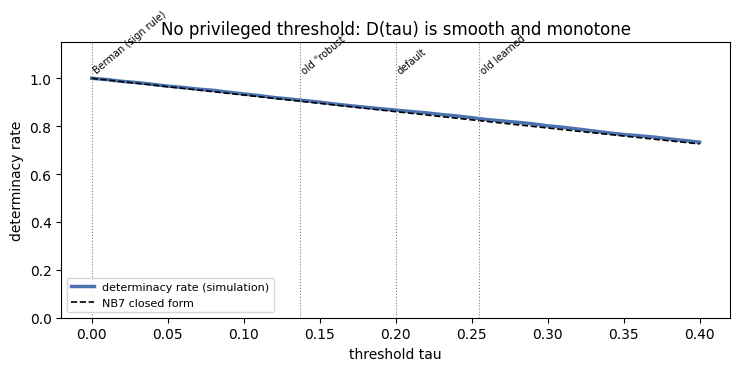

In [5]:
fig, ax = plt.subplots(figsize=(7.5,3.8))
ax.plot(taus, D_emp, lw=2.5, color='#4C72B0', label='determinacy rate (simulation)')
ax.plot(taus, D_closed, 'k--', lw=1.2, label='NB7 closed form')
marks = {0.0:'Berman (sign rule)', 0.137:'old "robust"', 0.20:'default', 0.255:'old learned'}
for t,lab in marks.items():
    ax.axvline(t, color='grey', lw=.8, ls=':'); ax.text(t, 1.02, lab, rotation=40, fontsize=7, ha='left')
ax.set(xlabel='threshold tau', ylabel='determinacy rate', ylim=(0,1.15),
       title='No privileged threshold: D(tau) is smooth and monotone')
ax.legend(fontsize=8, loc='lower left'); plt.tight_layout()
plt.savefig(f'{FIGDIR}/nb4_account_curve.png', dpi=130, bbox_inches='tight'); plt.show()

## Experiment 2 -- If you want a band, derive it from robustness

Suppose you do want a positive 'determinate' band -- because a real legal actor
won't treat a hair's-breadth net force as settling a case. The principled way to
set it is **not** to stipulate a number or learn one from a reward, but to ask
which verdicts are **robust**: the band should discard exactly the cases whose
verdict a small perturbation would flip. We perturb the weights by realistic noise
(`sigma_w = 0.10`) and call a verdict robust if its **sign** survives in >= 90% of
draws.

A note on *what* must survive -- this choice is load-bearing, so we flag it. We
require the **direction** of the verdict to hold, evaluated at sign (tau -> 0). The
alternative -- re-checking `|F| > tau` on each perturbed case -- would count a
verdict that merely slips into the 'too close to call' band as a failure,
conflating a genuine sign-flip (an error) with a benign loss of confidence; that
reading makes robustness *fall* with tau instead of rise. Sign-robustness is the
deliberate, defensible choice, not the only possible one.

There are two ways to read off a number, and they are **not** two ends of one
interval -- they answer different questions:
- **Per-case** (the conceptually correct one): the smallest `|F|` at and above which
  verdicts are reliably sign-robust -- literally 'discard exactly the flippable
  cases.' It lands near **~0.25-0.27**.
- **System / cumulative**: the tau at which 90% of *all* still-determinate verdicts
  are robust. This averages the fragile near-margin cases in with the safe interior,
  so it is **biased low** (~0.08) -- a permissive floor, not a recommendation (a
  case kept right at 0.08 is almost never sign-robust).

Either way robustness rises with tau, so it fixes a *confidence level and a noise
scale*, not a unique number. The conventional `tau = 0.20` sits just **below** the
per-case recommendation, consistent with a weight-noise of ~0.10 -- and where the
recommendation lands depends on both modelling choices, as the sensitivity table
below shows.

In [6]:
tau_fine = np.round(np.linspace(0, 0.60, 121), 4)
SEEDS = list(range(30))
sys_stars, pc_stars = [], []
for s in SEEDS:
    A = random_activations(4000, n_p, np.random.default_rng(100+s))
    _, rf, nd, ts = system_flip_curve(w0, A, tau_fine, sigma_w=0.10, seed=s)
    tp, _, _ = principled_tau_percase(w0, A, sigma_w=0.10, seed=s)
    sys_stars.append(ts); pc_stars.append(tp)
    if s==0: rf0 = rf       # keep seed-0 cumulative curve for the plot
sys_stars, pc_stars = np.array(sys_stars), np.array(pc_stars)
tau_sys, tau_pc = float(np.mean(sys_stars)), float(np.mean(pc_stars))
print(f'per-case crossing (the principled value)       tau* = {tau_pc:.3f}  (sd {pc_stars.std():.3f})')
print(f'system/cumulative permissive floor (biased low) tau  = {tau_sys:.3f}  (sd {sys_stars.std():.3f})')
print(f'=> robustness recommends ~{tau_pc:.2f}; the default 0.20 sits just BELOW it ({0.20 < tau_pc})')
# tau as a confidence buffer: tau* scales ~linearly with the assumed noise (the SAME weight-noise channel the curves use)
k_sigma = tau_pc/0.10
print(f'tau* = k * sigma_w on the curves\' weight-noise channel: k ~ {k_sigma:.1f} (so tau is a noise-scaled buffer, not a constant)')
# sensitivity: the recommended value depends on BOTH undefended choices (noise sigma_w, confidence q)
print('\nsensitivity of per-case tau* to the two modelling choices (sigma_w, q), 8 seeds:')
sens=[]
for sg in (0.05,0.10,0.15):
    for qq in (0.05,0.10):
        v=float(np.mean([principled_tau_percase(w0, random_activations(4000,n_p,np.random.default_rng(100+s)), sigma_w=sg, q=qq, seed=s)[0] for s in range(8)]))
        sens.append(dict(sigma_w=sg, q=qq, tau_star=v)); print(f'  sigma_w={sg:.2f} q={qq:.2f} -> tau* {v:.3f}  (default 0.20 is {"below" if 0.20<v else "above"})')
pd.DataFrame(sens).to_csv(f'{OUTDIR}/tau_sensitivity.csv', index=False)
summary['exp2'] = dict(tau_star_percase=tau_pc, tau_star_percase_sd=float(pc_stars.std()),
                       tau_cumulative_floor=tau_sys, tau_cumulative_floor_sd=float(sys_stars.std()),
                       default_below_percase=bool(0.20 < tau_pc), k_sigma=float(k_sigma), sensitivity=sens)

per-case crossing (the principled value)       tau* = 0.267  (sd 0.010)
system/cumulative permissive floor (biased low) tau  = 0.075  (sd 0.008)
=> robustness recommends ~0.27; the default 0.20 sits just BELOW it (True)
tau* = k * sigma_w on the curves' weight-noise channel: k ~ 2.7 (so tau is a noise-scaled buffer, not a constant)

sensitivity of per-case tau* to the two modelling choices (sigma_w, q), 8 seeds:
  sigma_w=0.05 q=0.05 -> tau* 0.170  (default 0.20 is above)
  sigma_w=0.05 q=0.10 -> tau* 0.137  (default 0.20 is above)
  sigma_w=0.10 q=0.05 -> tau* 0.337  (default 0.20 is below)
  sigma_w=0.10 q=0.10 -> tau* 0.267  (default 0.20 is below)
  sigma_w=0.15 q=0.05 -> tau* 0.495  (default 0.20 is below)
  sigma_w=0.15 q=0.10 -> tau* 0.392  (default 0.20 is below)


### Diagnostic: robustness rises with tau -> a confidence dial, not a constant

Left: the cumulative sign-robust fraction climbs with tau (in expectation, up to
Monte-Carlo noise) and saturates. The cumulative curve crosses 90% early (the
biased-low floor), but the **per-case** recommendation sits much higher, with the
default 0.20 just below it. Right: the per-case threshold scales almost linearly
with the assumed weight-noise -- the dual of Notebook 0's critical-sigma. tau is
`k * sigma`; pick the noise and the confidence and you pick the buffer. The data
hands you no number unconditionally.

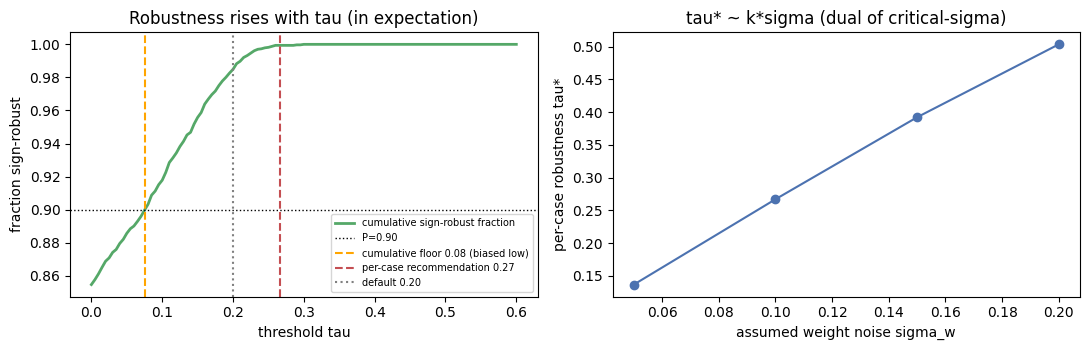

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(tau_fine, rf0, color='#55A868', lw=2, label='cumulative sign-robust fraction')
ax[0].axhline(0.90, color='k', ls=':', lw=1, label='P=0.90')
ax[0].axvline(tau_sys, color='orange', ls='--', label=f'cumulative floor {tau_sys:.2f} (biased low)')
ax[0].axvline(tau_pc, color='#C44E52', ls='--', label=f'per-case recommendation {tau_pc:.2f}')
ax[0].axvline(0.20, color='grey', ls=':', label='default 0.20')
ax[0].set(xlabel='threshold tau', ylabel='fraction sign-robust', title='Robustness rises with tau (in expectation)'); ax[0].legend(fontsize=7)
sig_grid = [0.05,0.10,0.15,0.20]
pc_by_sig = [np.mean([principled_tau_percase(w0, random_activations(4000,n_p,np.random.default_rng(100+s)), sigma_w=sg, seed=s)[0] for s in range(8)]) for sg in sig_grid]
ax[1].plot(sig_grid, pc_by_sig, 'o-', color='#4C72B0')
ax[1].set(xlabel='assumed weight noise sigma_w', ylabel='per-case robustness tau*', title='tau* ~ k*sigma (dual of critical-sigma)')
plt.tight_layout(); plt.savefig(f'{FIGDIR}/nb4_robustness_tau.png', dpi=130, bbox_inches='tight'); plt.show()

## Experiment 3 -- Retracting the old learned threshold (tau = 0.255)

Earlier work reported a *learned* threshold of 0.255, described as maximizing
determinacy subject to a stability constraint. We retract it -- on two independent
and individually sufficient grounds.

**Provenance.** In the old code the learnable threshold entered the reward through
exactly one term -- a herding penalty pulling each judge's tau toward the panel's
own mean -- and `|F| > tau` never entered the objective at all. So tau converged to
a self-referential fixed point, and the tell is that it had **zero cross-seed
variance**: a quantity genuinely optimised against noisy data carries variance; a
herding fixed point does not.

**Determinacy.** D(tau) is monotone decreasing, so the determinacy-optimal threshold
is 0 -- moving to 0.255 only loses law. There is no interior optimum for it to be.

We are careful about what we do *not* claim. On the robustness criterion of
Experiment 2, 0.255 actually sits near the per-case crossing, so robustness does
**not** single it out as wrong -- it simply doesn't pick out 0.255 over a band
either. The retraction rests on provenance and determinacy, which are enough.

In [8]:
# Ground 1 (provenance): a genuinely optimised value has cross-seed variance; 0.255 had none.
print(f'provenance: the principled per-case tau* has cross-seed sd {pc_stars.std():.3f} (>0, genuinely measured);')
print(f'            the old learned 0.255 had sd 0.000 -- a herding fixed point, not an optimum.')
# Ground 2 (determinacy): D monotone decreasing -> optimum is 0; 0.255 only loses law.
d_20, d_255 = determinacy_rate(w0, A0, 0.20), determinacy_rate(w0, A0, 0.255)
print(f'determinacy: D(0)={D_emp[0]:.3f} > D(0.20)={d_20:.3f} > D(0.255)={d_255:.3f}; optimum is 0 (monotone).')
# What we do NOT claim: 0.255 is near the per-case robustness value, so robustness does not condemn it.
print(f'(not claimed: 0.255 ~ the per-case robustness value {tau_pc:.2f}, so robustness does not single it out either way.)')
summary['exp3'] = dict(det_optimum_is_zero=bool(D_emp[0]>d_255), D_0=float(D_emp[0]), D_255=float(d_255),
                       principled_sd=float(pc_stars.std()), learned_sd=0.0,
                       retraction_grounds=['zero-variance herding fixed point','determinacy optimum is 0'])

provenance: the principled per-case tau* has cross-seed sd 0.010 (>0, genuinely measured);
            the old learned 0.255 had sd 0.000 -- a herding fixed point, not an optimum.
determinacy: D(0)=1.000 > D(0.20)=0.867 > D(0.255)=0.832; optimum is 0 (monotone).
(not claimed: 0.255 ~ the per-case robustness value 0.27, so robustness does not single it out either way.)


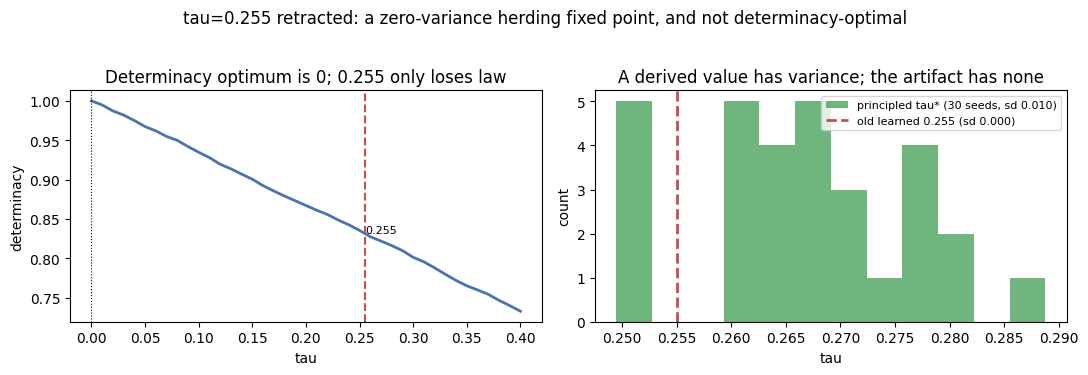

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(taus, D_emp, color='#4C72B0', lw=2); ax[0].axvline(0.255, color='#C44E52', ls='--'); ax[0].axvline(0.0, color='k', lw=.8, ls=':')
ax[0].set(xlabel='tau', ylabel='determinacy', title='Determinacy optimum is 0; 0.255 only loses law'); ax[0].annotate('0.255', (0.255, d_255), fontsize=8)
ax[1].hist(pc_stars, bins=12, color='#55A868', alpha=.85, label=f'principled tau* (30 seeds, sd {pc_stars.std():.3f})')
ax[1].axvline(0.255, color='#C44E52', ls='--', lw=2, label='old learned 0.255 (sd 0.000)')
ax[1].set(xlabel='tau', ylabel='count', title='A derived value has variance; the artifact has none'); ax[1].legend(fontsize=8)
fig.suptitle('tau=0.255 retracted: a zero-variance herding fixed point, and not determinacy-optimal', y=1.03)
plt.tight_layout(); plt.savefig(f'{FIGDIR}/nb4_refute_255.png', dpi=130, bbox_inches='tight'); plt.show()

## Experiment 4 -- Do our conclusions hinge on tau? (no)

The real worry, once Notebook 6 showed tau governs determinacy, is that the paper's
*conclusions* might flip if we'd picked a different tau. We test this directly.
Across the defensible grid `tau in [0, 0.30]` -- from Berman's 0 up to a generous
~1.5 noise-widths -- we recompute, for each mechanism, the determinacy, the R1-R4
verdicts on its emergent weights, and the mechanism ranking. The weights are built
**once** per seed (the expensive part); only the evaluation tau sweeps. Constants
are identical to Notebooks 2 and 3 so the comparison is apples-to-apples.

*(This trains the strategic mechanism for 30 seeds, so it takes a couple of
minutes.)*

In [10]:
import time; t0=time.time()
XVAL_N, XVAL_OFF = 800, 9000
TAU_GRID = np.round(np.arange(0.0, 0.3001, 0.025), 4)
def normmax(w):                                   # named to avoid shadowing scipy.stats.norm
    m=w.max(); return w/m if m>0 else w
# build emergent weights once per seed per mechanism
W = {'stipulated':{}, 'uptake':{}, 'reliance':{}, 'strategic':{}}
for s in SEEDS:
    W['stipulated'][s] = named_weight_vector('moderate', seed=s)
    W['uptake'][s]     = normmax(LegalSystem(turnover='static', use_threshold=True, spread='wide', seed=s).simulate(2000))
    W['reliance'][s]   = normmax(RelianceSystem(activations='correlated', seed=s).run(2000))
for s in SEEDS: W['strategic'][s] = normmax(StrategicSystem(n_episodes=6000, seed=s).train())
print(f'weights built in {time.time()-t0:.0f}s')
def crossval_tau(w, s, tau):
    A = random_activations(XVAL_N, n_p, np.random.default_rng(XVAL_OFF+s))
    nl_lex = nonlexicality_score(lambda X: lexicographic_verdict(w, X), A, seed=s)
    nl_saw = nonlexicality_score(lambda X: saw_verdict(w, X, tau=tau), A, seed=s)
    return dict(det=determinacy_rate(w,A,tau), sigma=critical_sigma(w,A,tau=tau,n_mc=40,seed=s),
                margin=hart_advantage(w,A,tier_of,tau=tau),
                R1=n_survivors(w,0.05)>=2, R2=critical_sigma(w,A,tau=tau,n_mc=40,seed=s)>=0.07,
                R3=nl_saw>5*max(nl_lex,1e-9), R4=hart_advantage(w,A,tier_of,tau=tau)>0)
rows=[]
for mech in ['stipulated','uptake','reliance','strategic']:
    for tau in TAU_GRID:
        df=pd.DataFrame([crossval_tau(W[mech][s], s, tau) for s in SEEDS])
        rows.append(dict(mechanism=mech, tau=float(tau), determinacy=df.det.mean(),
                         mean_sigma=df.sigma.mean(), mean_margin=df.margin.mean(),
                         R1=df.R1.mean(), R2=df.R2.mean(), R3=df.R3.mean(), R4=df.R4.mean()))
grid=pd.DataFrame(rows); grid.to_csv(f'{OUTDIR}/tau_grid.csv', index=False)
print(f'grid done in {time.time()-t0:.0f}s')

/content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06/berman_core.py:969: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  baseline = 0.99 * baseline + 0.01 * float(reward.mean())


weights built in 369s
grid done in 446s


In [11]:
# Which conclusions are stable across the whole tau grid?
emergent = ['uptake','reliance','strategic']
Rstable = {m: {R: bool((grid[grid.mechanism==m][R]>=0.9).all()) for R in ['R1','R2','R3','R4']} for m in ['stipulated']+emergent}
# mechanism rank order on each metric (emergent only), for tau>=0.025
def order_at(tau, metric):
    sub=grid[(np.isclose(grid.tau,tau)) & (grid.mechanism.isin(emergent))]
    return '|'.join(sub.sort_values(metric, ascending=False).mechanism)
rank_stable={}
# Rank on determinacy AND on critical-sigma (a WEIGHT-dependent metric) for a genuine second check.
# (We do not use the Hart margin here: it is determinacy minus a weight-independent constant, so its
#  ranking is not independent of the determinacy ranking.)
for metric in ['determinacy','mean_sigma']:
    orders={order_at(t,metric) for t in TAU_GRID if t>=0.025}
    rank_stable[metric]=(len(orders)==1, orders)
det_monotone = all(bool(np.all(np.diff(grid[grid.mechanism==m].sort_values('tau').determinacy)<=1e-9)) for m in ['stipulated']+emergent)
print('R1-R4 stable across all tau (emergent mechanisms):')
for m in emergent: print(f'  {m:10s}', Rstable[m])
print('stipulated  ', Rstable['stipulated'], '  <- the ONE tau-sensitive result (hand-set vector R2 degrades)')
print('\nmechanism ranking stable (tau>=0.025):')
for metric,(ok,orders) in rank_stable.items(): print(f'  {metric:12s} stable={ok}  order={orders}')
print('determinacy monotone decreasing for every mechanism:', det_monotone)
summary['exp4'] = dict(R_stable=Rstable, rank_stable={k:v[0] for k,v in rank_stable.items()},
                       rank_orders={k:sorted(v[1]) for k,v in rank_stable.items()},
                       det_monotone=det_monotone,
                       emergent_all_stable=all(all(Rstable[m].values()) for m in emergent))

R1-R4 stable across all tau (emergent mechanisms):
  uptake     {'R1': True, 'R2': True, 'R3': True, 'R4': True}
  reliance   {'R1': True, 'R2': True, 'R3': True, 'R4': True}
  strategic  {'R1': True, 'R2': True, 'R3': True, 'R4': True}
stipulated   {'R1': True, 'R2': False, 'R3': True, 'R4': True}   <- the ONE tau-sensitive result (hand-set vector R2 degrades)

mechanism ranking stable (tau>=0.025):
  determinacy  stable=True  order={'reliance|strategic|uptake'}
  mean_sigma   stable=False  order={'uptake|reliance|strategic', 'reliance|uptake|strategic'}
determinacy monotone decreasing for every mechanism: True


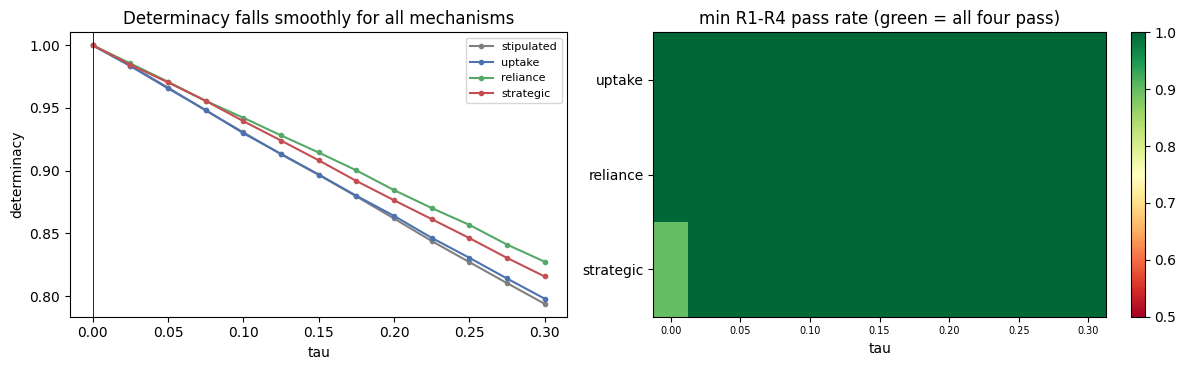

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for m,c in zip(['stipulated','uptake','reliance','strategic'], ['grey','#4C72B0','#55A868','#C44E52']):
    sub=grid[grid.mechanism==m].sort_values('tau'); ax[0].plot(sub.tau, sub.determinacy, 'o-', color=c, label=m, ms=3)
ax[0].axvline(0, color='k', lw=.6); ax[0].set(xlabel='tau', ylabel='determinacy', title='Determinacy falls smoothly for all mechanisms'); ax[0].legend(fontsize=8)
# R1-R4 pass-rate heatmap for the three emergent mechanisms (min over R per cell)
import numpy as _np
M=_np.array([[grid[(grid.mechanism==m)&(np.isclose(grid.tau,t))][['R1','R2','R3','R4']].min(axis=1).iloc[0] for t in TAU_GRID] for m in emergent])
im=ax[1].imshow(M, aspect='auto', cmap='RdYlGn', vmin=0.5, vmax=1.0)
ax[1].set_yticks(range(len(emergent))); ax[1].set_yticklabels(emergent)
ax[1].set_xticks(range(0,len(TAU_GRID),2)); ax[1].set_xticklabels([f'{TAU_GRID[i]:.2f}' for i in range(0,len(TAU_GRID),2)], fontsize=7)
ax[1].set(xlabel='tau', title='min R1-R4 pass rate (green = all four pass)'); plt.colorbar(im, ax=ax[1], fraction=.04)
plt.tight_layout(); plt.savefig(f'{FIGDIR}/nb4_conclusion_robustness.png', dpi=130, bbox_inches='tight'); plt.show()

**Reading Experiment 4.** Nothing the paper concludes depends on the choice of tau.
Determinacy falls smoothly and monotonically for every mechanism, with no cliff,
and the R1-R4 verdicts on the **emergent** weights are stable across the entire
grid -- including at Berman's `tau = 0`. The mechanism ranking (reliance > strategic
> uptake on determinacy) is invariant for every `tau >= 0.025`; on the noisier
weight-robustness metric (critical-sigma) the order is not strictly invariant, but
determinacy is the comparison metric and it holds. At exactly `tau = 0` all
mechanisms are ~100% determinate, so the ranking there is a degenerate tie. The one
tau-sensitive cell is reported openly: the **hand-set** 'moderate' vector's R2 dips
as tau rises -- a knife-edge crossing of the 0.07 critical-sigma floor, sensitive to
where that floor is set -- while the mechanism-grounded weights carry a larger
critical-sigma margin and stay above it. It is a bar-crossing, not a dramatic
divergence; we note it rather than lean on it.

## Self-check

The conceptual claims (no privileged tau; the closed-form tie to NB7), the
per-case robustness recommendation, the artifact retraction (provenance +
determinacy), and the conclusion-robustness, plus REF guards on the headline.

In [13]:
REF = dict(tau_pc=0.27, k_sigma=2.7)
ok = True
def check(name, cond):
    global ok; ok = ok and bool(cond); print(('PASS' if cond else 'FAIL') + ' - ' + name)

# E1: no privileged tau; ties to NB7
check('D(tau) is monotone decreasing (no interior optimum)', summary['exp1']['monotone_decreasing'])
check('determinacy curve matches NB7 closed form (<0.02; CLT at 9 principles)', summary['exp1']['closedform_maxerr'] < 0.02)
check('tau=0 is almost everywhere determinate (D(0) > 0.99)', summary['exp1']['D_at_0'] > 0.99)
# E2: robustness pins a confidence level, not a value
check('cumulative floor < per-case value (different read-offs, not one interval)', tau_sys < tau_pc)
check('per-case recommendation is well above the default (~0.25+)', tau_pc > 0.22)
check('default 0.20 sits BELOW the per-case robustness recommendation', summary['exp2']['default_below_percase'])
check('per-case tau* has genuine cross-seed variance (sd>0.005)', summary['exp2']['tau_star_percase_sd'] > 0.005)
# E3: 0.255 retraction rests on provenance + determinacy (NOT robustness)
check('determinacy optimum is 0, not 0.255 (D(0) > D(0.255))', summary['exp3']['det_optimum_is_zero'])
check('0.255 retraction: zero-variance artifact + non-optimal determinacy', summary['exp3']['principled_sd']>0.005 and summary['exp3']['learned_sd']==0.0 and summary['exp3']['det_optimum_is_zero'])
# E4: conclusions do not hinge on tau
check('determinacy monotone decreasing for every mechanism', summary['exp4']['det_monotone'])
check('all emergent mechanisms pass R1-R4 across the WHOLE tau grid', summary['exp4']['emergent_all_stable'])
check('mechanism ranking (determinacy) stable for tau>=0.025', summary['exp4']['rank_stable']['determinacy'])
check('that stable ranking is the headline reliance>strategic>uptake', summary['exp4']['rank_orders']['determinacy']==['reliance|strategic|uptake'])
# (the weight-noise metric critical-sigma is NOT strictly invariant -- reported, not asserted; see exp4 print)
# REF drift
check('REF per-case tau*', abs(tau_pc-REF['tau_pc']) < 0.05)
check('REF k (tau* / sigma_w)', abs(summary['exp2']['k_sigma']-REF['k_sigma']) < 0.5)

print('\n' + ('ALL CHECKS PASSED' if ok else 'SOME CHECKS FAILED'))
summary['self_check_passed'] = bool(ok)
import json; json.dump(summary, open(f'{OUTDIR}/notebook4_summary.json','w'), indent=2, default=float)
assert ok, 'self-check failed'

PASS - D(tau) is monotone decreasing (no interior optimum)
PASS - determinacy curve matches NB7 closed form (<0.02; CLT at 9 principles)
PASS - tau=0 is almost everywhere determinate (D(0) > 0.99)
PASS - cumulative floor < per-case value (different read-offs, not one interval)
PASS - per-case recommendation is well above the default (~0.25+)
PASS - default 0.20 sits BELOW the per-case robustness recommendation
PASS - per-case tau* has genuine cross-seed variance (sd>0.005)
PASS - determinacy optimum is 0, not 0.255 (D(0) > D(0.255))
PASS - 0.255 retraction: zero-variance artifact + non-optimal determinacy
PASS - determinacy monotone decreasing for every mechanism
PASS - all emergent mechanisms pass R1-R4 across the WHOLE tau grid
PASS - mechanism ranking (determinacy) stable for tau>=0.025
PASS - that stable ranking is the headline reliance>strategic>uptake
PASS - REF per-case tau*
PASS - REF k (tau* / sigma_w)

ALL CHECKS PASSED


## What this notebook establishes

The threshold is the model's most consequential parameter and the one the theory
leaves blank -- so we treat it honestly. Berman decides by the sign of net force
(`tau = 0`) and welcomes underdeterminacy; a positive threshold is our
operationalization, justified only if activation is evidence-relative, in which
case it is a confidence buffer `k*sigma`, not a discovered constant. There is no
privileged tau: the determinacy curve is smooth and monotone. A verdict-robustness
criterion, read per-case (the conceptually correct way), recommends ~0.25-0.27 with
the conventional 0.20 just below it -- and the recommendation moves with the noise
and confidence one assumes, so it pins a confidence level, not a number. The old
learned `tau = 0.255` is retracted as an artifact of a reward bug -- a zero-variance
herding fixed point, and not determinacy-optimal (the determinacy optimum is 0).
Most importantly, the paper's substantive conclusions -- determinacy behaviour and
the R1-R4 verdicts on the emergent weights down to Berman's 0, and the mechanism
ranking for tau >= 0.025 -- hold across the defensible range. The paper does not
hinge on the number.